# Video Game Sales Prediction on Steam Data
## Notebook 1 of 3 — Preprocessing and Transformation

**Objective.** Predict the sales of PC games, measured as estimated Steam owners, from information
that is available when a game is released.

**Approach.** The study applies the modeling approach of Gray, Shalan and Kadlec (*Sales Predictions
for Video Games Using Predictive Analytics of Market Data*, IEEE CICN 2024) to a new dataset:
- **Retained from the parent paper:** Linear Regression and Decision Tree models, evaluated with
  MSE, RMSE, MAE, MAPE and R².
- **Added:** Random Forest, and 5-fold cross-validation in addition to a held-out test set.
- **Removed:** the parent paper's choice of predictors. Its model used regional sales, which sum to
  the global-sales target, and user review counts, which accumulate after release. Both give the
  model information that is not available when a sales forecast is needed. This study uses only
  variables that exist at release.

Models are run with their standard (default) settings to establish a baseline. Modifications are
left for later iterations and are informed by the issues identified in Notebook 3.

**Analysis pipeline**

| Stage | Notebook | Content |
|---|---|---|
| 1. Preprocessing | 01 | Data introduction, data wrangling, variable selection |
| 2. Transformation | 01 | Target variable and feature encoding |
| 3. Analysis | 02 | Descriptive statistics, target distribution, relationships with sales |
| 4. Modeling | 03 | Data split, Linear Regression, Decision Tree, Random Forest |
| 5. Validation | 03 | 5-fold cross-validation, held-out test set, error analysis |
| 6. Decision making | 03 | Model comparison, important variables, issues and next steps |

In [1]:
import json
import os
import re

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
import kagglehub

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
})

FIG_DIR = os.path.join("..", "outputs", "figures")
TAB_DIR = os.path.join("..", "outputs", "tables")
DATA_DIR = os.path.join("..", "data", "processed")
for d in (FIG_DIR, TAB_DIR, DATA_DIR):
    os.makedirs(d, exist_ok=True)

RELEASE_CUTOFF = pd.Timestamp("2024-06-30")  # last release date with complete owner data (Section 2.4)

C:\Users\Nobutaka\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


---
# 1. Data Introduction

**Source.** [Steam Games Dataset](https://www.kaggle.com/datasets/fronkongames/steam-games-dataset)
(Kaggle, fronkongames, version 49), which combines two public sources:

- **Steam store pages** — information shown to customers: price, release date, developer and
  publisher, genres, feature categories, supported languages, platforms, screenshots and
  description.
- **SteamSpy** — estimated number of owners per game, reported as ranges (for example,
  20,000 – 50,000), together with engagement statistics such as review counts and playtime.

**Version.** The download is pinned to dataset version 49. The dataset is re-scraped periodically
(version 51 appeared in September 2026), so pinning keeps every result in this project reproducible.

**Unit of analysis.** One row per Steam application (AppID).

**Target.** Estimated number of owners, used as the measure of sales. Steam does not publish unit
sales; SteamSpy owner estimates are the standard public substitute.

**Relevance.** The parent paper's dataset (VGChartz) ends in 2016 and records little about a game
beyond genre, platform, publisher and year. The Steam data covers recent releases and records
product characteristics that are set before release, such as price, localisation and platform
support.

In [2]:
path = kagglehub.dataset_download("fronkongames/steam-games-dataset/versions/49")
with open(os.path.join(path, "games.json"), encoding="utf-8") as f:
    raw_json = json.load(f)


def first_package_text(v):
    for p in v.get("packages") or []:
        for s in p.get("subs") or []:
            if s.get("text"):
                return s["text"]
    return None


records = []
for appid, v in raw_json.items():
    records.append({
        "appid": int(appid),
        "name": v.get("name"),
        "release_date": v.get("release_date"),
        "estimated_owners": v.get("estimated_owners"),
        "price_current": v.get("price"),
        "package_text": first_package_text(v),
        "required_age": v.get("required_age"),
        "detailed_description": v.get("detailed_description") or "",
        "windows": v.get("windows"), "mac": v.get("mac"), "linux": v.get("linux"),
        "supported_languages": v.get("supported_languages") or [],
        "full_audio_languages": v.get("full_audio_languages") or [],
        "categories": v.get("categories") or [],
        "genres": v.get("genres") or [],
        "n_screenshots": len(v.get("screenshots") or []),
        "n_movies": len(v.get("movies") or []),
        "metacritic_score": v.get("metacritic_score"),
        "positive": v.get("positive"), "negative": v.get("negative"),
        "recommendations": v.get("recommendations"),
        "peak_ccu": v.get("peak_ccu"),
        "average_playtime_forever": v.get("average_playtime_forever"),
        "tags": v.get("tags") or {},
    })
del raw_json

df = pd.DataFrame(records)
print(f"Applications: {len(df):,} | fields retained: {df.shape[1]}")
df[["appid", "name", "release_date", "price_current", "estimated_owners", "genres"]].head(3)

Applications: 141,900 | fields retained: 24


,appid,name,release_date,price_current,estimated_owners,genres
0,2539430,Black Dragon Mage Playtest,"Aug 1, 2023",0.00,0 - 0,[]
1,496350,Supipara - Chapter 1 Spring Has Come!,"Jul 29, 2016",5.24,0 - 20000,[Adventure]
2,1034400,Mystery Solitaire The Black Raven,"May 6, 2019",4.99,0 - 20000,[Casual]


---
# 2. Preprocessing (Data Wrangling)

## 2.1 Source file selection

The dataset is distributed as `games.csv` and `games.json`. The CSV header merges two field names
(`Discount` and `DLC count`) into one (`DiscountDLC count`), so the header has one fewer name than
each data row and a standard reader assigns every value to the wrong column (for example, the game
title is read as `AppID`). The JSON file does not have this defect and contains more applications.
**All processing uses `games.json`.**

In [3]:
csv_path = os.path.join(path, "games.csv")
csv_header = pd.read_csv(csv_path, nrows=0).columns.tolist()
csv_rows = len(pd.read_csv(csv_path, usecols=[0], index_col=False, low_memory=False))
print(f"games.csv : {len(csv_header)} header names, merged name present: {'DiscountDLC count' in csv_header}, {csv_rows:,} rows")
print(f"games.json: {len(df):,} applications")
print(f"Applications with trailer data: {(df['n_movies'] > 0).sum()} (trailer information is empty in this version)")

games.csv : 39 header names, merged name present: True, 125,855 rows
games.json: 141,900 applications
Applications with trailer data: 0 (trailer information is empty in this version)


## 2.2 Parsing dates and owner ranges

Release dates are stored as text (`"Jul 29, 2016"`) and owner estimates as a range string
(`"20000 - 50000"`). Both are converted to typed columns.

In [4]:
df["release_dt"] = pd.to_datetime(df["release_date"], errors="coerce", format="mixed")
bounds = df["estimated_owners"].str.extract(r"(\d+)\s*-\s*(\d+)").astype(float)
df["owners_low"], df["owners_high"] = bounds[0], bounds[1]

print(f"Unparseable release dates: {df['release_dt'].isna().sum()}")
order = df.drop_duplicates("estimated_owners").sort_values("owners_low")["estimated_owners"]
df["estimated_owners"].value_counts().reindex(order).rename("applications").to_frame().T

Unparseable release dates: 0


estimated_owners,0 - 0,0 - 20000,20000 - 50000,50000 - 100000,100000 - 200000,200000 - 500000,500000 - 1000000,1000000 - 2000000,2000000 - 5000000,5000000 - 10000000,10000000 - 20000000,20000000 - 50000000,50000000 - 100000000,100000000 - 200000000
applications,38990,77328,11400,5359,3457,2857,1155,729,405,125,51,31,9,4


## 2.3 Validity of the owner labels

**Issue.** About 27% of applications report `"0 - 0"` owners. This value could mean either very low
sales or that SteamSpy never collected data for the application.

**Test.** A game with genuinely low sales still shows some player activity. The table compares
`"0 - 0"` applications with the lowest genuine range (`"0 - 20000"`).

In [5]:
zero = df["estimated_owners"] == "0 - 0"
low = df["estimated_owners"] == "0 - 20000"
reviews = df["positive"] + df["negative"]
evidence = pd.DataFrame({
    '"0 - 0"': [(reviews[zero] > 0).mean(), (df.loc[zero, "peak_ccu"] > 0).mean(),
                (df.loc[zero, "average_playtime_forever"] > 0).mean(), (df.loc[zero, "tags"].str.len() > 0).mean()],
    '"0 - 20000"': [(reviews[low] > 0).mean(), (df.loc[low, "peak_ccu"] > 0).mean(),
                    (df.loc[low, "average_playtime_forever"] > 0).mean(), (df.loc[low, "tags"].str.len() > 0).mean()],
}, index=["share with any review", "share with peak players > 0", "share with playtime > 0", "share with user tags"])
evidence.style.format("{:.1%}")

,"""0 - 0""","""0 - 20000"""
share with any review,0.0%,74.3%
share with peak players > 0,0.0%,10.1%
share with playtime > 0,0.0%,12.6%
share with user tags,0.0%,74.8%


**Finding.** Every SteamSpy-derived field is empty for all `"0 - 0"` applications, whereas most games
in the lowest genuine range have reviews and user tags. `"0 - 0"` therefore indicates a **missing
label**, not zero sales. **Resolution:** these rows are excluded.

## 2.4 Label coverage over time

**Issue.** If SteamSpy stopped updating its estimates at some point, games released after that
point would be unlabeled, and games released shortly before it would not yet have accumulated
their sales.

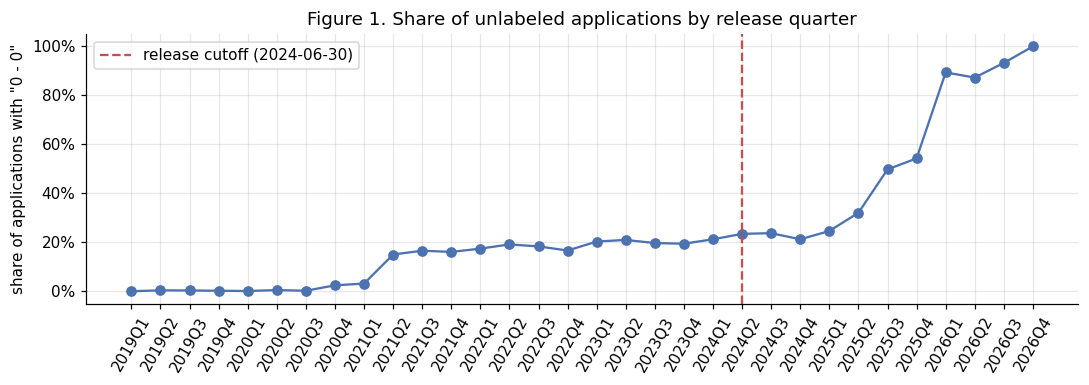

In [6]:
recent = df[df["release_dt"] >= "2019-01-01"]
by_q = recent.groupby(recent["release_dt"].dt.to_period("Q")).agg(
    applications=("appid", "size"), share_unlabeled=("estimated_owners", lambda s: (s == "0 - 0").mean()))

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(by_q.index.astype(str), by_q["share_unlabeled"], marker="o", color="#4C72B0")
ax.axvline(str(RELEASE_CUTOFF.to_period("Q")), color="#C44E52", ls="--", label=f"release cutoff ({RELEASE_CUTOFF.date()})")
ax.set_ylabel('share of applications with "0 - 0"')
ax.set_title("Figure 1. Share of unlabeled applications by release quarter")
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.tick_params(axis="x", rotation=60)
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig01_unlabeled_share_by_quarter.png"), dpi=150)
plt.show()

**Finding.** The unlabeled share is stable at about 20–25% until early 2025, then rises to about 50%
in the second half of 2025 and about 90% in 2026. Owner estimates stopped updating around mid-2025.

**Resolution.** Only games released **on or before 30 June 2024** are retained, so every game has at
least twelve months of owner data.

## 2.5 Scope: standalone games only

**Issue.** Steam also lists applications that are not commercial game products:
- **Playtests and demos**, published as separate free AppIDs;
- **Software** such as utilities and video, design or development tools.

**Resolution.** Playtests and demos are identified by name. An application is classed as software
when it carries a software genre and none of the core game genres.

In [7]:
name_l = df["name"].fillna("").str.lower()
is_test_build = name_l.str.contains(r"\bplaytest\b|\bdemo\b")

SOFTWARE_GENRES = {"Utilities", "Design & Illustration", "Animation & Modeling", "Video Production",
                   "Game Development", "Photo Editing", "Audio Production", "Software Training",
                   "Web Publishing", "Accounting"}
GAME_GENRES = {"Action", "Adventure", "Casual", "RPG", "Simulation", "Strategy", "Sports", "Racing",
               "Massively Multiplayer"}
is_software = df["genres"].apply(lambda L: bool(SOFTWARE_GENRES & set(L)) and not (GAME_GENRES & set(L)))
is_labeled = df["estimated_owners"] != "0 - 0"
released = df["release_dt"] <= RELEASE_CUTOFF

steps = [
    ("All applications in games.json", pd.Series(True, index=df.index)),
    ("Remove playtests and demos", ~is_test_build),
    ("Remove non-game software", ~is_software),
    ('Remove missing labels ("0 - 0")', is_labeled),
    (f"Keep releases up to {RELEASE_CUTOFF.date()}", released),
]
mask = pd.Series(True, index=df.index)
funnel = []
for label, cond in steps:
    mask &= cond
    funnel.append({"step": label, "rows remaining": int(mask.sum())})
funnel = pd.DataFrame(funnel)
funnel["rows removed"] = (-funnel["rows remaining"].diff()).fillna(0).astype(int)

games = df[mask].copy().reset_index(drop=True)
funnel

,step,rows remaining,rows removed
0,All applications in games.json,141900,0
1,Remove playtests and demos,133688,8212
2,Remove non-game software,132243,1445
3,"Remove missing labels (""0 - 0"")",101630,30613
4,Keep releases up to 2024-06-30,76727,24903


## 2.6 Variable selection: removing information not available at release

**Issue in the parent paper.** The parent paper predicted global sales using the four regional
sales columns, which add up exactly to global sales, together with critic and user review counts.
A model given the components of its own target reproduces the target by addition (hence its
R² = 1.000), and review counts only exist after a game has been sold. Such a model cannot be used
to forecast the sales of a game at release.

**Rule applied here.** A variable is used only if its value is known on the release date.
Variables measured on players after release are excluded. The Steam equivalents of the parent
paper's predictors would leak in the same way, as their correlation with the target shows:

In [8]:
chk = games.assign(reviews=games["positive"] + games["negative"],
                   owners_mid=(games["owners_low"] + games["owners_high"]) / 2)
pd.DataFrame({
    "Spearman correlation with owners": [
        chk[c].corr(chk["owners_mid"], method="spearman")
        for c in ["reviews", "recommendations", "peak_ccu", "average_playtime_forever"]]
}, index=["review count", "recommendations", "peak concurrent players", "average playtime"]).round(3)

,Spearman correlation with owners
review count,0.601
recommendations,0.584
peak concurrent players,0.502
average playtime,0.591


In [9]:
audit = pd.DataFrame([
    ("List price", "Used", "Set before release. The current price is not used because it includes later discounts."),
    ("Release year, required age", "Used", "Known at release."),
    ("Supported languages, audio languages, platforms", "Used", "Declared on the store page at release."),
    ("Screenshots, description length", "Used", "Store-page content prepared for release."),
    ("Genres, feature categories", "Used", "Chosen by the developer, except the entries listed below."),
    ("Genre 'Early Access'", "Excluded", "Reflects status at the data snapshot; games that complete Early Access lose the label."),
    ("Categories added after release", "Excluded", "Trading Cards and Family Sharing (granted or applied by Valve after release); "
     "Achievements, Workshop, In-App Purchases, Remote Play, Cross-Platform Multiplayer and recent accessibility labels "
     "(commonly added in later updates)."),
    ("Metacritic score", "Excluded", "Available for only about 5% of games."),
    ("Reviews, recommendations, user score", "Excluded", "Accumulate after release (equivalent to the parent paper's User_Count)."),
    ("Peak players, playtime, user tags, DLC count", "Excluded", "Measured or created after release."),
    ("Developer, publisher", "Excluded", "Thousands of distinct values; not used in the parent paper either."),
], columns=["Variable", "Decision", "Reason"])
audit.to_csv(os.path.join(TAB_DIR, "table_variable_selection.csv"), index=False)
audit

,Variable,Decision,Reason
0,List price,Used,Set before release. The current price is not u...
1,"Release year, required age",Used,Known at release.
2,"Supported languages, audio languages, platforms",Used,Declared on the store page at release.
3,"Screenshots, description length",Used,Store-page content prepared for release.
4,"Genres, feature categories",Used,"Chosen by the developer, except the entries li..."
5,Genre 'Early Access',Excluded,Reflects status at the data snapshot; games th...
6,Categories added after release,Excluded,Trading Cards and Family Sharing (granted or a...
7,Metacritic score,Excluded,Available for only about 5% of games.
8,"Reviews, recommendations, user score",Excluded,Accumulate after release (equivalent to the pa...
9,"Peak players, playtime, user tags, DLC count",Excluded,Measured or created after release.


---
# 3. Transformation

## 3.1 Target variable

The target is the **estimated number of owners, in millions**, taken as the midpoint of each
SteamSpy range (for example, 20,000 – 50,000 becomes 0.035 million). Millions are used to match the
unit of the parent paper's `Global_Sales`. The target is kept on its original scale for this
baseline; its distribution is examined in Notebook 2.

In [10]:
games["owners_millions"] = (games["owners_low"] + games["owners_high"]) / 2 / 1e6
games["owners_millions"].describe().to_frame().T.round(4)

,count,mean,std,min,25%,50%,75%,max
owners_millions,76727.0,0.1256,1.5842,0.01,0.01,0.01,0.035,150.0


## 3.2 Features

Store-page fields are converted into numeric features:

| Feature | Construction |
|---|---|
| `price` | List price in USD, read from the purchase package text (e.g. `"Game – $14.99 $5.24"` → 14.99); the current price where no package text exists |
| `release_year` | Year of the release date |
| `required_age` | Minimum age set on the store page (0 = none) |
| `n_languages`, `n_audio_languages` | Number of supported interface and full-audio languages |
| `mac`, `linux` | 1 if the game supports the platform (nearly all games support Windows) |
| `n_screenshots` | Number of screenshots on the store page |
| `description_length` | Number of characters in the store description |
| `genre_*`, `cat_*` | One binary column per genre and feature category (the most frequent 15 genres and 18 categories) |

In [11]:
def list_price(row):
    txt = row["package_text"]
    if isinstance(txt, str):
        m = re.search(r"\$(\d+(?:\.\d+)?)", txt)
        if m:
            return float(m.group(1))
    return float(row["price_current"] or 0.0)


games["price"] = games.apply(list_price, axis=1)
games["release_year"] = games["release_dt"].dt.year
games["required_age"] = games["required_age"].fillna(0).astype(float)
games["n_languages"] = games["supported_languages"].str.len()
games["n_audio_languages"] = games["full_audio_languages"].str.len()
games["mac"] = games["mac"].astype(int)
games["linux"] = games["linux"].astype(int)
games["description_length"] = games["detailed_description"].str.len()

EXCLUDED_GENRES = {"Early Access"}
EXCLUDED_CATEGORIES = {
    "Steam Trading Cards", "Family Sharing", "Steam Achievements", "Steam Workshop", "In-App Purchases",
    "Cross-Platform Multiplayer", "Remote Play Together", "Remote Play on TV", "Remote Play on Phone",
    "Remote Play on Tablet", "Custom Volume Controls", "Playable without Timed Input", "Stereo Sound",
    "Surround Sound", "Save Anytime", "Mouse Only Option", "Keyboard Only Option", "Touch Only Option",
    "Camera Comfort", "Adjustable Difficulty", "Color Alternatives", "Adjustable Text Size", "Subtitle Options",
    "Narrated Game Menus", "Chat Text-to-speech", "Chat Speech-to-text", "Steam Timeline",
    "DualShock Controller Support", "DualSense Controller Support", "Gamepad Recommended",
}


def one_hot(series, prefix, top_n, exclude):
    cleaned = series.apply(lambda L: [x for x in L if x not in exclude])
    keep = cleaned.explode().dropna().value_counts().head(top_n).index
    out = pd.DataFrame(index=series.index)
    for k in keep:
        out[prefix + re.sub(r"[^0-9a-zA-Z]+", "_", k).strip("_")] = cleaned.apply(lambda L, k=k: int(k in L))
    return out


genre_cols = one_hot(games["genres"], "genre_", 15, EXCLUDED_GENRES)
category_cols = one_hot(games["categories"], "cat_", 18, EXCLUDED_CATEGORIES)
games = pd.concat([games, genre_cols, category_cols], axis=1)
print(f"List price differs from current price for {(games['price'] != games['price_current']).mean():.1%} of games")
print("Genres:", ", ".join(c[6:] for c in genre_cols.columns))
print("Categories:", ", ".join(c[4:] for c in category_cols.columns))

List price differs from current price for 51.4% of games
Genres: Indie, Casual, Action, Adventure, Simulation, Strategy, RPG, Free_To_Play, Sports, Racing, Massively_Multiplayer, Violent, Gore, Education, Nudity
Categories: Single_player, Steam_Cloud, Full_controller_support, Multi_player, Partial_Controller_Support, PvP, Co_op, Steam_Leaderboards, Online_PvP, Shared_Split_Screen, Tracked_Controller_Support, VR_Only, Online_Co_op, Shared_Split_Screen_PvP, Stats, Shared_Split_Screen_Co_op, Includes_level_editor, Captions_available


## 3.3 Output

The modeling table contains the identifiers, the target and the features. Post-release variables
are not written to the file, so they cannot enter a model by mistake.

In [12]:
NUMERIC_FEATURES = ["price", "release_year", "required_age", "n_languages", "n_audio_languages",
                    "mac", "linux", "n_screenshots", "description_length"]
FEATURES = NUMERIC_FEATURES + list(genre_cols.columns) + list(category_cols.columns)
TARGET = "owners_millions"

model_table = games[["appid", "name", "release_dt", "estimated_owners", TARGET] + FEATURES]
assert model_table[FEATURES + [TARGET]].isna().sum().sum() == 0

model_table.to_csv(os.path.join(DATA_DIR, "steam_model_table.csv.gz"), index=False)
with open(os.path.join(DATA_DIR, "features.json"), "w") as f:
    json.dump({"target": TARGET, "numeric": NUMERIC_FEATURES, "genres": list(genre_cols.columns),
               "categories": list(category_cols.columns)}, f, indent=2)
print(f"Saved modeling table: {len(model_table):,} games, {len(FEATURES)} features, no missing values")

Saved modeling table: 76,727 games, 42 features, no missing values


## Summary of Notebook 1

- **Data:** 141,900 Steam applications, loaded from JSON because the CSV header is malformed.
- **Wrangling:** `"0 - 0"` owner values were identified as missing labels and removed; games released
  after June 2024 were removed because their owner data is incomplete; playtests, demos and
  software were removed.
- **Variable selection:** the parent paper's approach of using regional sales and review counts
  was removed; only variables known at release are kept.
- **Transformation:** target = estimated owners in millions; 42 numeric and binary features.